In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [4]:
plt.style.use('dark_background')
plt.rcParams['figure.figsize'] = (10,8)

# Criar o Dataset

In [39]:
def get_linear_curve(x, w, b=0, noise_scale=0):
  return w*x + b + noise_scale*np.random.randn(x.shape[0])

In [40]:
x = np.arange(-10, 30.10, 0.5)
Y = get_linear_curve(x, 1.8, 32, noise_scale=5)

In [41]:
x.shape
x[-1]

np.float64(30.0)

In [42]:
x

array([-10. ,  -9.5,  -9. ,  -8.5,  -8. ,  -7.5,  -7. ,  -6.5,  -6. ,
        -5.5,  -5. ,  -4.5,  -4. ,  -3.5,  -3. ,  -2.5,  -2. ,  -1.5,
        -1. ,  -0.5,   0. ,   0.5,   1. ,   1.5,   2. ,   2.5,   3. ,
         3.5,   4. ,   4.5,   5. ,   5.5,   6. ,   6.5,   7. ,   7.5,
         8. ,   8.5,   9. ,   9.5,  10. ,  10.5,  11. ,  11.5,  12. ,
        12.5,  13. ,  13.5,  14. ,  14.5,  15. ,  15.5,  16. ,  16.5,
        17. ,  17.5,  18. ,  18.5,  19. ,  19.5,  20. ,  20.5,  21. ,
        21.5,  22. ,  22.5,  23. ,  23.5,  24. ,  24.5,  25. ,  25.5,
        26. ,  26.5,  27. ,  27.5,  28. ,  28.5,  29. ,  29.5,  30. ])

In [43]:
x.shape, Y.shape

((81,), (81,))

Text(0, 0.5, 'ºF')

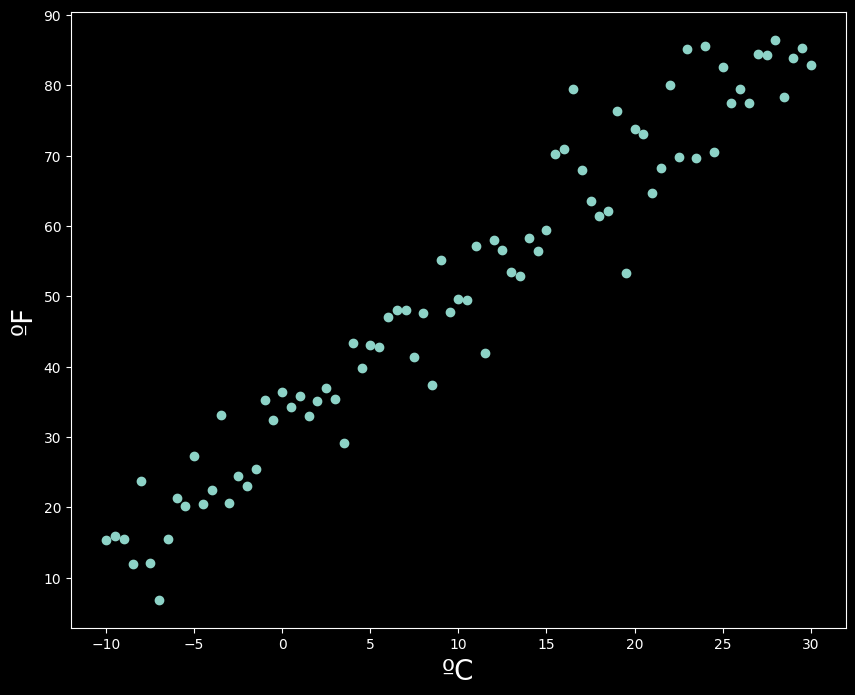

In [44]:
plt.scatter(x, Y)
plt.xlabel("ºC", fontsize=20)
plt.ylabel("ºF", fontsize=20)

(array([1.0000e+00, 4.0000e+00, 7.0000e+00, 3.4000e+01, 7.1000e+01,
        1.5800e+02, 3.2700e+02, 7.9900e+02, 1.5870e+03, 2.6850e+03,
        4.4080e+03, 6.5760e+03, 8.6710e+03, 1.0382e+04, 1.1741e+04,
        1.2053e+04, 1.1195e+04, 9.4430e+03, 7.3420e+03, 5.1750e+03,
        3.3310e+03, 1.9990e+03, 1.0560e+03, 5.6200e+02, 2.2600e+02,
        1.1200e+02, 3.6000e+01, 1.7000e+01, 0.0000e+00, 2.0000e+00]),
 array([-4.60421471, -4.30151312, -3.99881152, -3.69610993, -3.39340833,
        -3.09070674, -2.78800514, -2.48530355, -2.18260195, -1.87990036,
        -1.57719876, -1.27449717, -0.97179557, -0.66909398, -0.36639238,
        -0.06369079,  0.23901081,  0.5417124 ,  0.844414  ,  1.14711559,
         1.44981719,  1.75251878,  2.05522038,  2.35792197,  2.66062357,
         2.96332516,  3.26602676,  3.56872835,  3.87142995,  4.17413154,
         4.47683314]),
 <BarContainer object of 30 artists>)

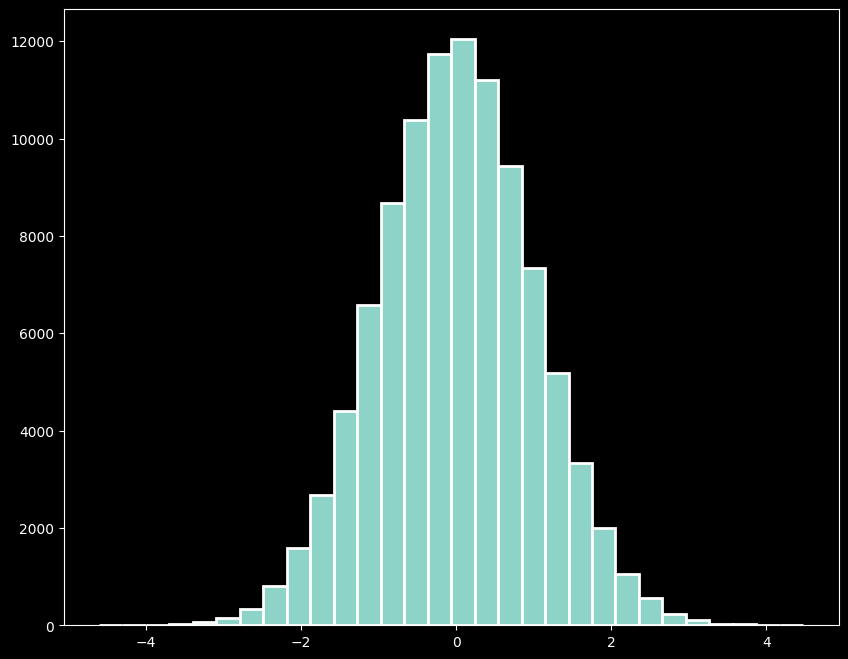

In [32]:
plt.hist(np.random.randn(100000), bins=30, edgecolor='white', linewidth=2)

# Modelo

- inicializar os pesos e bias
- Feedforward
- Calcular a perda
- Backpropagation

In [45]:
# Inicializar
w = np.random.rand(1)
b = 0

In [46]:
def forward(inputs, w, b):
  return w*inputs + b

In [47]:
# funcao de perda
def mse(Y, y_pred):
  return(Y-y_pred)**2

In [50]:
valor_real = np.array([3, 4, 5])
u = np.array([3.2, 4.5, 4.8])

mse(valor_real, u) # .sum() .mean()

array([0.04, 0.25, 0.04])

In [66]:
def backpropagation(inputs, outputs, targets, w, b, learn_rate):
  derivada_erro_peso = learn_rate*(-2*inputs*(targets-outputs)).mean()
  derivada_erro_bias = learn_rate*(-2*(targets-outputs)).mean()

  w -= derivada_erro_peso
  b -= derivada_erro_bias
  return w, b

In [67]:
def model_fit(inputs, targets, w, b, epochs = 200, learn_rate = 0.01):
  for epoch in range(epochs):

    outputs = forward(inputs, w, b)
    loss = np.mean(mse(targets, outputs))
    w, b = backpropagation(inputs, outputs, targets, w, b, learn_rate)

    if (epoch+1) % 50 == 0:
      print(f"Epoch: [{(epoch+1)}/{epochs}] Loss: [{loss:.4f}]")
  return w, b


In [152]:
x = np.arange(-10, 30, 2)
Y = get_linear_curve(x, 1.8, 32, noise_scale=2)

In [156]:
# Inicializacao
w =  np.random.randn(1)
b = np.zeros(1)

In [162]:
w, b = model_fit(w, Y, w, b, epochs=200, learn_rate=0.009)
print(f'w: {w[0]:.3f}, b: {b[0]:.3f}')

Epoch: [50/200] Loss: [440.8301]
Epoch: [100/200] Loss: [440.8301]
Epoch: [150/200] Loss: [440.8301]
Epoch: [200/200] Loss: [440.8301]
w: -6.560, b: 4.634


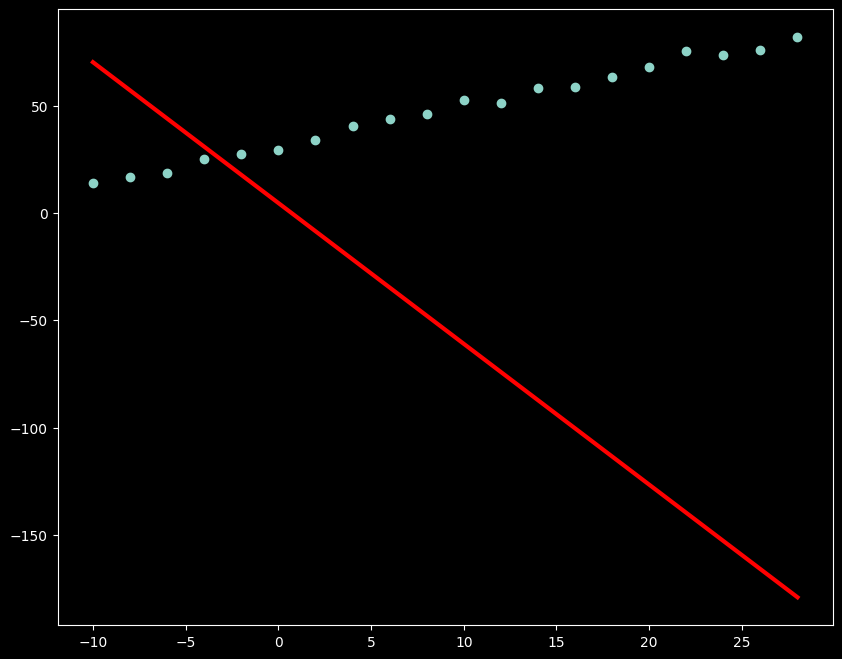

In [163]:
plt.scatter(x, Y)
plt.plot(x, get_linear_curve(x, w, b),'r', lw=3)